# 컨텍스트 분리와 Isolate

**이 노트북에서 할 일**

1. 대출과 인사 두 업무가 섞인 대화 기록을 만듭니다.
2. 대화 전체를 모델에 보내고, 모델이 받은 메시지를 확인합니다(Before).
3. 현재 업무의 메시지만 골라 보내는 훅을 만들어 같은 대화를 보냅니다(After).

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 3번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

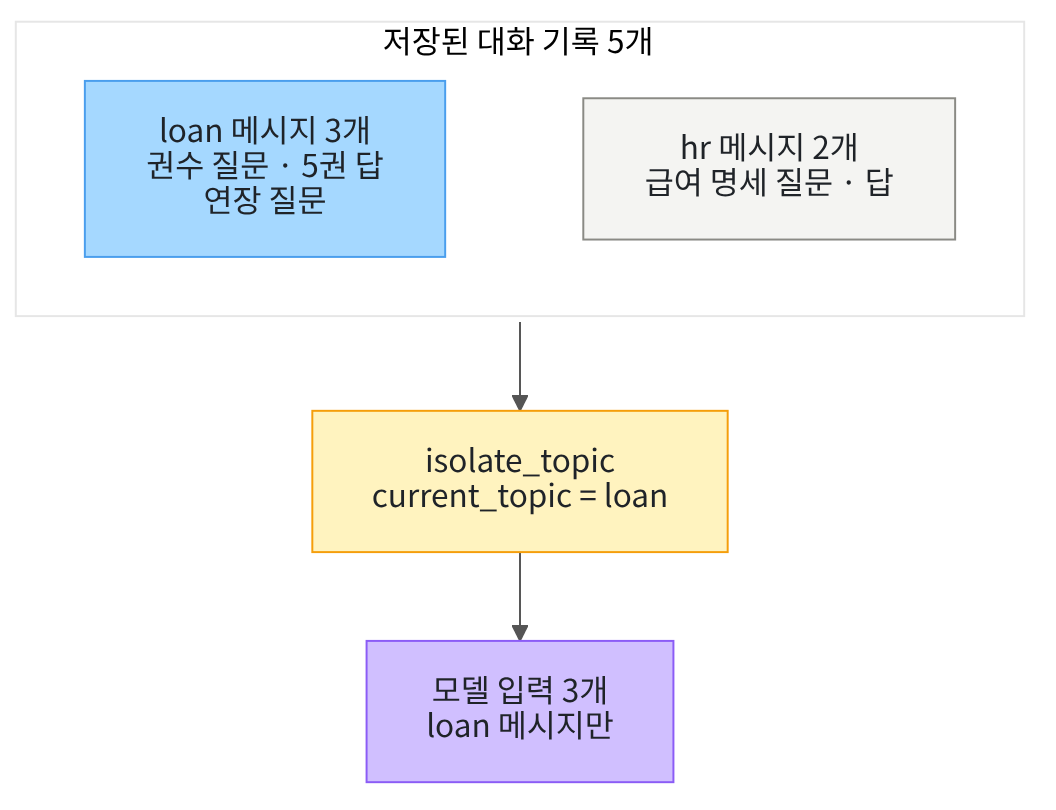

위는 저장된 대화 기록 다섯 개, 아래는 모델이 받은 메시지입니다. 분리 훅이 대출 메시지만 골라 보냅니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다.

In [2]:
# 에이전트·훅·메시지·모델을 만드는 도구를 불러옵니다
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import ModelRequest, ModelResponse, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, HumanMessage

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 업무가 섞인 대화 만들기

컨텍스트 분리(Isolate)는 대화 기록에서 지금 업무에 필요한 메시지만 골라 모델에 보내는 방법입니다. Ch8에서 배운 전략입니다.
메시지의 `additional_kwargs` 속성은 메시지에 추가 정보를 담아 두는 딕셔너리입니다.
여기에 업무 이름표 `topic`을 붙입니다. 이름표 중 loan은 대출, hr은 인사 업무입니다.

In [5]:
# 대출(loan)과 인사(hr) 업무가 섞인 대화 5개를 만듭니다
mixed = [
    HumanMessage("대출은 몇 권까지 되나요?", additional_kwargs={"topic": "loan"}),
    AIMessage("한 번에 5권까지 빌릴 수 있습니다.", additional_kwargs={"topic": "loan"}),
    HumanMessage("직원 급여 명세는 어디서 보나요?", additional_kwargs={"topic": "hr"}),
    AIMessage("급여 명세는 인사팀 내부 문서에 있습니다.", additional_kwargs={"topic": "hr"}),
    HumanMessage("대출 기간을 연장할 수 있나요?", additional_kwargs={"topic": "loan"}),
]
print("대화 메시지 수:", len(mixed))

대화 메시지 수: 5


**결과 읽기** — 대화 메시지 수는 `5`입니다. 마지막 질문은 대출 업무입니다.

02절과 같은 기록 훅을 만듭니다.

In [6]:
# 모델이 실제로 받은 메시지를 기록하는 훅을 만듭니다
seen_by_model = []


@wrap_model_call
def record_model_input(request: ModelRequest, handler: Callable) -> ModelResponse:
    for message in request.messages:
        seen_by_model.append(message.text)
    return handler(request)

출력은 없습니다.

## 3. Before — 대화 전체 보내기

In [7]:
# Before: 대화 전체를 그대로 보냅니다
plain_agent = create_agent(model, tools=[], middleware=[record_model_input])
plain_agent.invoke({"messages": mixed})
for text in seen_by_model:
    print("-", text)

- 대출은 몇 권까지 되나요?
- 한 번에 5권까지 빌릴 수 있습니다.
- 직원 급여 명세는 어디서 보나요?
- 급여 명세는 인사팀 내부 문서에 있습니다.
- 대출 기간을 연장할 수 있나요?


**결과 읽기** — 모델이 받은 글 다섯 개 중에 `직원 급여 명세는 어디서 보나요?`가 있습니다. 대출 질문에 필요 없는 인사 업무 내용입니다.

In [8]:
# 모델 입력에 인사 업무 내용이 섞였는지 확인합니다
has_salary = False
for text in seen_by_model:
    if "급여" in text:
        has_salary = True
print("모델 입력 메시지 수:", len(seen_by_model))
print("급여 내용이 섞였나:", has_salary)
assert has_salary

모델 입력 메시지 수: 5
급여 내용이 섞였나: True


**결과 읽기** — 모델 입력 메시지 수는 `5`, 급여 내용이 섞였는지 확인한 결과는 `True`입니다.

## 4. After — 현재 업무의 메시지만 보내기

지금 처리할 업무 이름을 변수에 담습니다.

In [9]:
# 지금 처리할 업무 이름을 정합니다
current_topic = "loan"
print("현재 업무:", current_topic)

현재 업무: loan


**결과 읽기** — 현재 업무는 `loan`입니다.

분리 훅은 모델을 부르기 전에 메시지를 하나씩 보고, 이름표가 현재 업무와 같은 것만 새 목록에 담습니다.
메서드 `request.override(messages=selected)`는 요청의 메시지만 바꾼 새 요청을 만듭니다. 대화 기록에는 쓰지 않으므로 저장된 기록은 줄지 않습니다.

In [10]:
# 현재 업무 이름표가 붙은 메시지만 골라 모델에 보내는 훅
@wrap_model_call
def isolate_topic(request: ModelRequest, handler: Callable) -> ModelResponse:
    selected = []
    for message in request.messages:
        if message.additional_kwargs.get("topic") == current_topic:
            selected.append(message)
    new_request = request.override(messages=selected)
    return handler(new_request)

출력은 없습니다. 분리 훅을 기록 훅보다 앞에 두어야, 기록 훅이 고른 뒤의 메시지를 봅니다.

In [11]:
# After: 분리 훅을 등록하고 같은 대화를 보냅니다
seen_by_model.clear()
isolated_agent = create_agent(model, tools=[], middleware=[isolate_topic, record_model_input])
isolated_result = isolated_agent.invoke({"messages": mixed})
for text in seen_by_model:
    print("-", text)

- 대출은 몇 권까지 되나요?
- 한 번에 5권까지 빌릴 수 있습니다.
- 대출 기간을 연장할 수 있나요?


**결과 읽기** — 모델이 받은 글이 대출 업무 세 개로 줄었습니다. 마지막 글은 `대출 기간을 연장할 수 있나요?`이고 급여 질문은 보이지 않습니다.

In [12]:
# 모델이 받은 메시지 수와 저장된 대화 기록을 비교합니다
stored = isolated_result["messages"]
print("모델 입력 메시지 수:", len(seen_by_model))
print("저장된 대화 기록 수:", len(stored))
print("기록의 세 번째 메시지:", stored[2].text)
print("새 답의 topic 이름표:", stored[-1].additional_kwargs.get("topic"))
assert len(seen_by_model) == 3

모델 입력 메시지 수: 3
저장된 대화 기록 수: 6
기록의 세 번째 메시지: 직원 급여 명세는 어디서 보나요?
새 답의 topic 이름표: None


**결과 읽기** — 모델 입력 메시지 수는 `3`입니다. 저장된 대화 기록 수는 `6`입니다. 원래 5개에 새 답 1개가 더해졌습니다.
기록의 세 번째 메시지로 급여 질문이 그대로 남아 있습니다. 새 답의 이름표는 `None`, 즉 없습니다.

분리는 모델에 보내는 요청만 줄였고, 저장된 기록에서는 아무것도 지우지 않았습니다.

## 5. 값 하나 바꿔 보기 — 업무 이름 바꾸기

`current_topic` 값을 hr로 바꿉니다. 실행 전에 예상해 봅니다. 인사 업무 메시지 2개만 모델에 갈 것입니다.

In [13]:
# 현재 업무를 인사(hr)로 바꿔 같은 대화를 보냅니다
current_topic = "hr"
seen_by_model.clear()
isolated_agent.invoke({"messages": mixed})
print("모델 입력 메시지 수:", len(seen_by_model))
for text in seen_by_model:
    print("-", text)

모델 입력 메시지 수: 2
- 직원 급여 명세는 어디서 보나요?
- 급여 명세는 인사팀 내부 문서에 있습니다.


**결과 읽기** — 모델 입력 메시지 수가 `2`입니다. 이번에는 대출 메시지가 빠지고 인사 업무 메시지만 남았습니다.

## 정리

- 분리 훅은 모델 요청에 들어갈 메시지만 골랐습니다. 저장된 대화 기록에서 지운 메시지는 없었습니다(5개에 새 답이 더해져 6개).
- 이름표(`topic`)를 붙여 두어야 코드로 업무를 구분할 수 있습니다.
- 모델 입력에서 빠졌다고 해서 접근이 막힌 것은 아닙니다. 급여 같은 내부 정보의 접근 권한은 별도로 관리해야 합니다.